In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
#Loading the dataset
df = pd.read_csv(
    "online+shoppers+purchasing+intention+dataset.zip",
    compression="zip"
)

print("Rows and columns:", df.shape)
display(df.head())


Rows and columns: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:

# Show all column names
print(df.columns.tolist())

# Show data types
df.info()

# Summary statistics
display(df.describe())


['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [9]:

# Check missing values
print(df.isnull().sum())

# Total missing values
print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())



Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64
Total missing values: 0
Duplicate rows: 125


In [10]:
# Check negative counts and durations
columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration"
]

for col in columns:
    print(col, (df[col] < 0).sum())

# Check rates outside 0 to 1
print("Invalid BounceRates:",
      (~df["BounceRates"].between(0, 1)).sum())

print("Invalid ExitRates:",
      (~df["ExitRates"].between(0, 1)).sum())

Administrative 0
Administrative_Duration 0
Informational 0
Informational_Duration 0
ProductRelated 0
ProductRelated_Duration 0
Invalid BounceRates: 0
Invalid ExitRates: 0


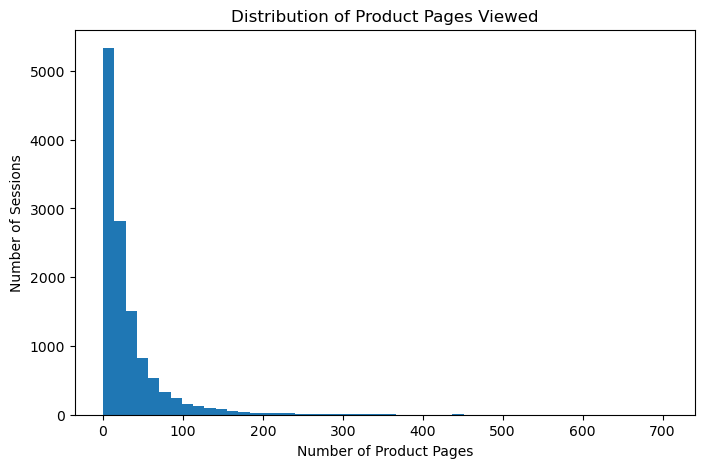

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(df["ProductRelated"], bins=50)

plt.title("Distribution of Product Pages Viewed")
plt.xlabel("Number of Product Pages")
plt.ylabel("Number of Sessions")

plt.show()

In [12]:
features = [
    "ProductRelated",
    "ProductRelated_Duration",
    "Administrative",
    "Informational",
    "BounceRates",
    "ExitRates"
]

X = df[features].copy()

X.head()

,ProductRelated,ProductRelated_Duration,Administrative,Informational,BounceRates,ExitRates
0,1,0.000000,0,0,0.20,0.20
1,2,64.000000,0,0,0.00,0.10
2,1,0.000000,0,0,0.20,0.20
3,2,2.666667,0,0,0.05,0.14
4,10,627.500000,0,0,0.02,0.05


In [13]:
log_columns = [
    "ProductRelated",
    "ProductRelated_Duration",
    "Administrative",
    "Informational"
]

X[log_columns] = np.log1p(X[log_columns])

X.head()

,ProductRelated,ProductRelated_Duration,Administrative,Informational,BounceRates,ExitRates
0,0.693147,0.000000,0.0,0.0,0.20,0.20
1,1.098612,4.174387,0.0,0.0,0.00,0.10
2,0.693147,0.000000,0.0,0.0,0.20,0.20
3,1.098612,1.299283,0.0,0.0,0.05,0.14
4,2.397895,6.443336,0.0,0.0,0.02,0.05


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(12330, 6)


In [15]:
print("Original dataset:", df.shape)
print("Clustering features:", X_scaled.shape)

print("Missing values:", df.isnull().sum().sum())

print("Ready for K-Means:",
      np.isfinite(X_scaled).all())

Original dataset: (12330, 18)
Clustering features: (12330, 6)
Missing values: 0
Ready for K-Means: True


In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2500,
        random_state=42
    )

    silhouette_scores.append(score)

    print("k =", k, "Silhouette Score =", round(score, 4))

k = 2 Silhouette Score = 0.5968
k = 3 Silhouette Score = 0.3627
k = 4 Silhouette Score = 0.3256
k = 5 Silhouette Score = 0.3387
k = 6 Silhouette Score = 0.3311
k = 7 Silhouette Score = 0.3389
k = 8 Silhouette Score = 0.3371


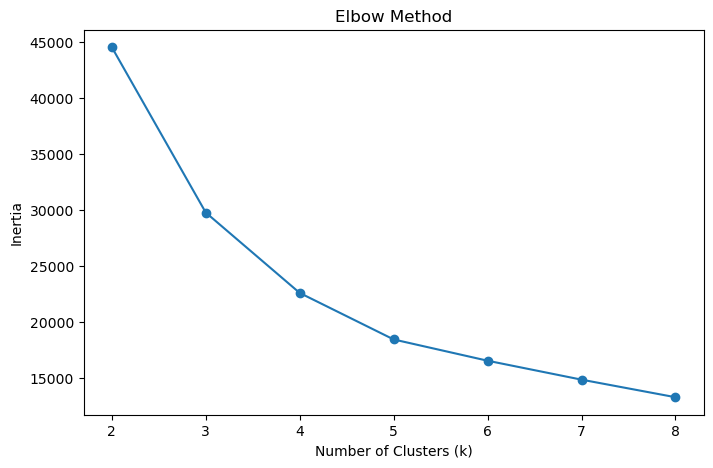

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertias, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")

plt.show()

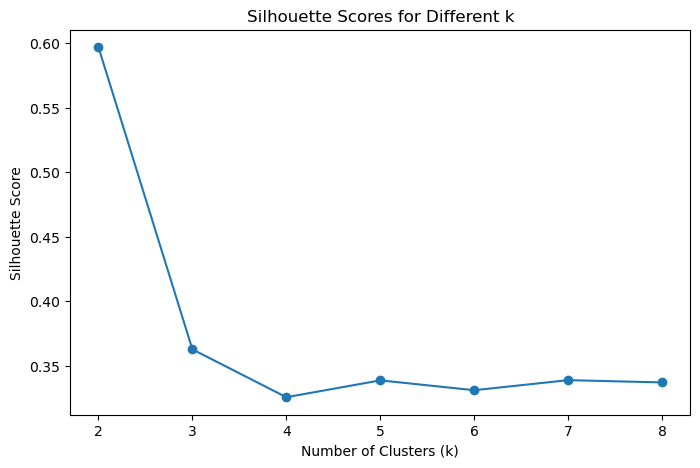

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_scores, marker="o")

plt.title("Silhouette Scores for Different k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")

plt.show()

In [19]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df["Cluster"].value_counts().sort_index())

Cluster
0    4224
1    7202
2     904
Name: count, dtype: int64


In [20]:
cluster_summary = df.groupby("Cluster").agg(
    Sessions=("Revenue", "size"),
    PurchaseRate=("Revenue", "mean"),
    MedianProductPages=("ProductRelated", "median"),
    MedianProductDuration=("ProductRelated_Duration", "median"),
    MedianBounceRate=("BounceRates", "median"),
    MedianExitRate=("ExitRates", "median")
)

cluster_summary["PurchaseRate"] *= 100

print(cluster_summary.round(2))

         Sessions  PurchaseRate  MedianProductPages  MedianProductDuration  \
Cluster                                                                      
0            4224         24.22                44.0                1625.78   
1            7202         12.23                12.0                 375.00   
2             904          0.44                 1.0                   0.00   

         MedianBounceRate  MedianExitRate  
Cluster                                    
0                     0.0            0.02  
1                     0.0            0.03  
2                     0.2            0.20  


In [21]:
for cluster in sorted(df["Cluster"].unique()):
    print("\nCluster:", cluster)

    examples = df[df["Cluster"] == cluster].head(2)

    display(
        examples[
            ["ProductRelated",
             "ProductRelated_Duration",
             "BounceRates",
             "ExitRates",
             "Revenue",
             "Cluster"]
        ]
    )


Cluster: 0


,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,Revenue,Cluster
26,32,1135.444444,0.002857,0.009524,False,0
29,45,1582.750000,0.043478,0.050821,False,0



Cluster: 1


,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,Revenue,Cluster
1,2,64.0,0.00,0.10,False,1
4,10,627.5,0.02,0.05,False,1



Cluster: 2


,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,Revenue,Cluster
0,1,0.0,0.2,0.2,False,2
2,1,0.0,0.2,0.2,False,2


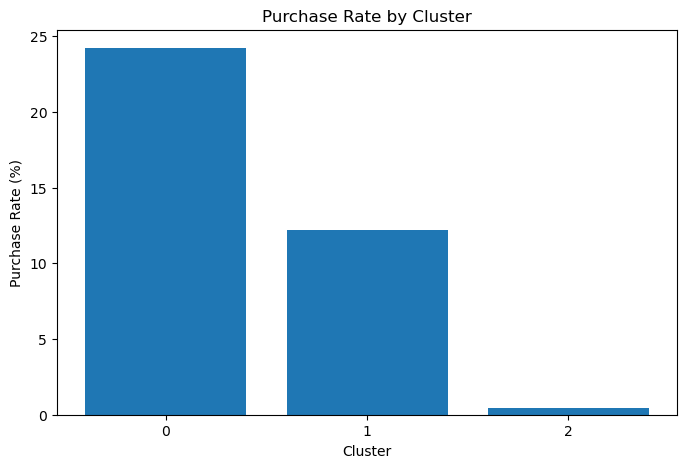

In [22]:
purchase_rates = df.groupby("Cluster")["Revenue"].mean() * 100

plt.figure(figsize=(8, 5))

plt.bar(
    purchase_rates.index.astype(str),
    purchase_rates.values
)

plt.title("Purchase Rate by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Purchase Rate (%)")

plt.show()